c:\Users\ma0026.NB-MA0026\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\ma0026.NB-MA0026\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


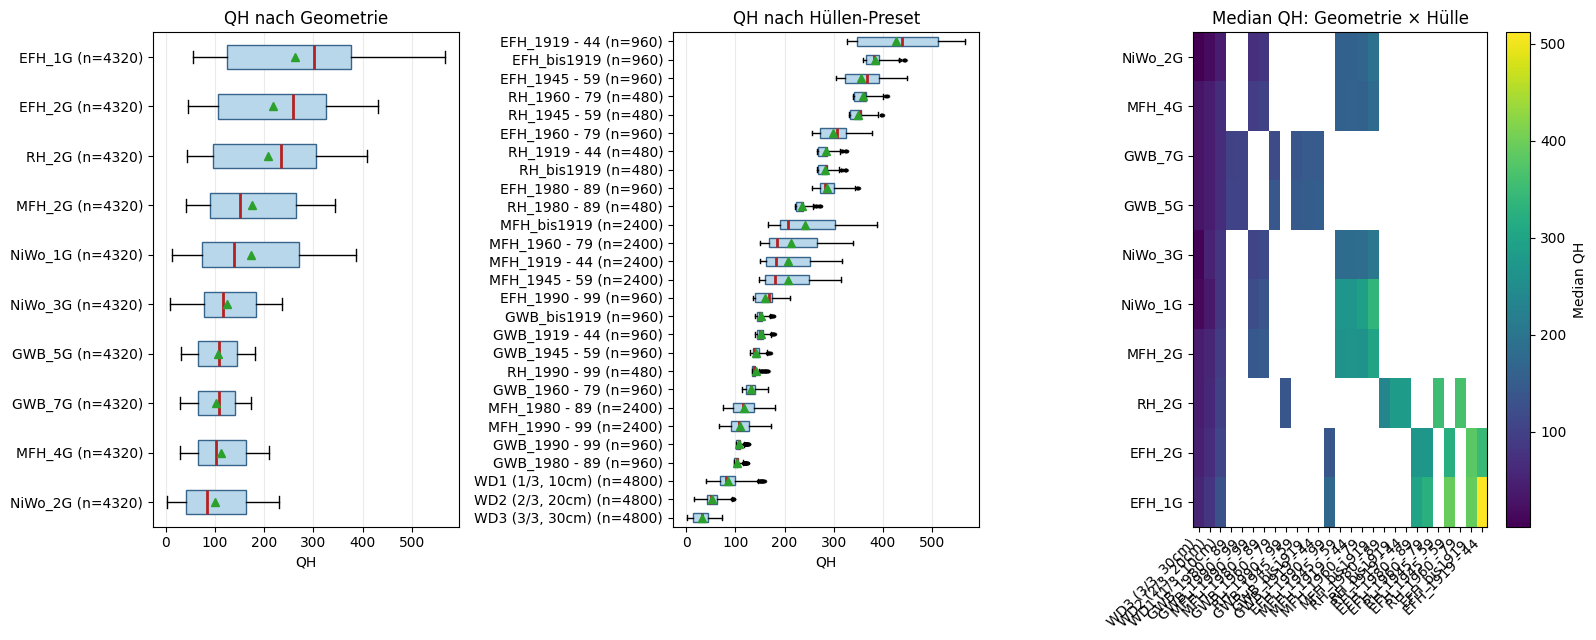

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

datei = Path(r"C:\Users\ma0026.NB-MA0026\Documents\peexcel\data\building_typologies\building_sector_v3\scenarios_harmonisiert.parquet")
geo, hull, wert = "preset_recorded_geometry", "preset_recorded_hulls", "QH"

df = pd.read_parquet(datei, columns=[geo, hull, wert])
df[wert] = pd.to_numeric(df[wert], errors="raise")
df[[geo, hull]] = df[[geo, hull]].astype("string").fillna("(fehlend)")
df = df.dropna(subset=[wert])

def boxplot(ax, spalte, titel):
    reihenfolge = df.groupby(spalte)[wert].median().sort_values().index
    gruppen = [df.loc[df[spalte] == k, wert] for k in reihenfolge]
    ax.boxplot(gruppen, vert=False, showmeans=True, patch_artist=True,
               boxprops=dict(facecolor="#b9d7ea", edgecolor="#36648b"),
               medianprops=dict(color="#b22222", linewidth=2),
               flierprops=dict(marker=".", markersize=3, alpha=0.4))
    ax.set_yticks(range(1, len(reihenfolge) + 1))
    ax.set_yticklabels([f"{k} (n={len(g)})" for k, g in zip(reihenfolge, gruppen)])
    ax.set_title(titel)
    ax.set_xlabel(wert)
    ax.grid(axis="x", alpha=0.25)

pivot = df.pivot_table(index=geo, columns=hull, values=wert, aggfunc="median")
pivot = pivot.loc[pivot.median(axis=1).sort_values().index,
                  pivot.median(axis=0).sort_values().index]

fig = plt.figure(figsize=(16, max(5, 0.45 * len(pivot) + 2)))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.2])
boxplot(fig.add_subplot(gs[0]), geo, "QH nach Geometrie")
boxplot(fig.add_subplot(gs[1]), hull, "QH nach Hüllen-Preset")

ax = fig.add_subplot(gs[2])
bild = ax.imshow(pivot.to_numpy(dtype=float), aspect="auto", cmap="viridis")
ax.set_xticks(range(pivot.shape[1]))
ax.set_xticklabels(pivot.columns, rotation=45, ha="right")
ax.set_yticks(range(pivot.shape[0]))
ax.set_yticklabels(pivot.index)
ax.set_title("Median QH: Geometrie × Hülle")
fig.colorbar(bild, ax=ax, label=f"Median {wert}")

if pivot.size <= 100:
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:,.0f}", ha="center", va="center",
                        fontsize=7, color="white")

plt.tight_layout()
plt.show()
# fig.savefig("QH_geometrie_huelle.png", dpi=200, bbox_inches="tight")

Geometrietyp -> Präfix -> Hüllen
EFH_1G -> EFH_ -> ['EFH_1919 - 44', 'EFH_1945 - 59', 'EFH_1960 - 79', 'EFH_1980 - 89', 'EFH_1990 - 99', 'EFH_bis1919']
EFH_2G -> EFH_ -> ['EFH_1919 - 44', 'EFH_1945 - 59', 'EFH_1960 - 79', 'EFH_1980 - 89', 'EFH_1990 - 99', 'EFH_bis1919']
GWB_5G -> GWB_ -> ['GWB_1919 - 44', 'GWB_1945 - 59', 'GWB_1960 - 79', 'GWB_1980 - 89', 'GWB_1990 - 99', 'GWB_bis1919']
GWB_7G -> GWB_ -> ['GWB_1919 - 44', 'GWB_1945 - 59', 'GWB_1960 - 79', 'GWB_1980 - 89', 'GWB_1990 - 99', 'GWB_bis1919']
MFH_2G -> MFH_ -> ['MFH_1919 - 44', 'MFH_1945 - 59', 'MFH_1960 - 79', 'MFH_1980 - 89', 'MFH_1990 - 99', 'MFH_bis1919']
MFH_4G -> MFH_ -> ['MFH_1919 - 44', 'MFH_1945 - 59', 'MFH_1960 - 79', 'MFH_1980 - 89', 'MFH_1990 - 99', 'MFH_bis1919']
NiWo_1G -> MFH_ -> ['MFH_1919 - 44', 'MFH_1945 - 59', 'MFH_1960 - 79', 'MFH_1980 - 89', 'MFH_1990 - 99', 'MFH_bis1919']
NiWo_2G -> MFH_ -> ['MFH_1919 - 44', 'MFH_1945 - 59', 'MFH_1960 - 79', 'MFH_1980 - 89', 'MFH_1990 - 99', 'MFH_bis1919']
NiWo_3G -> MF

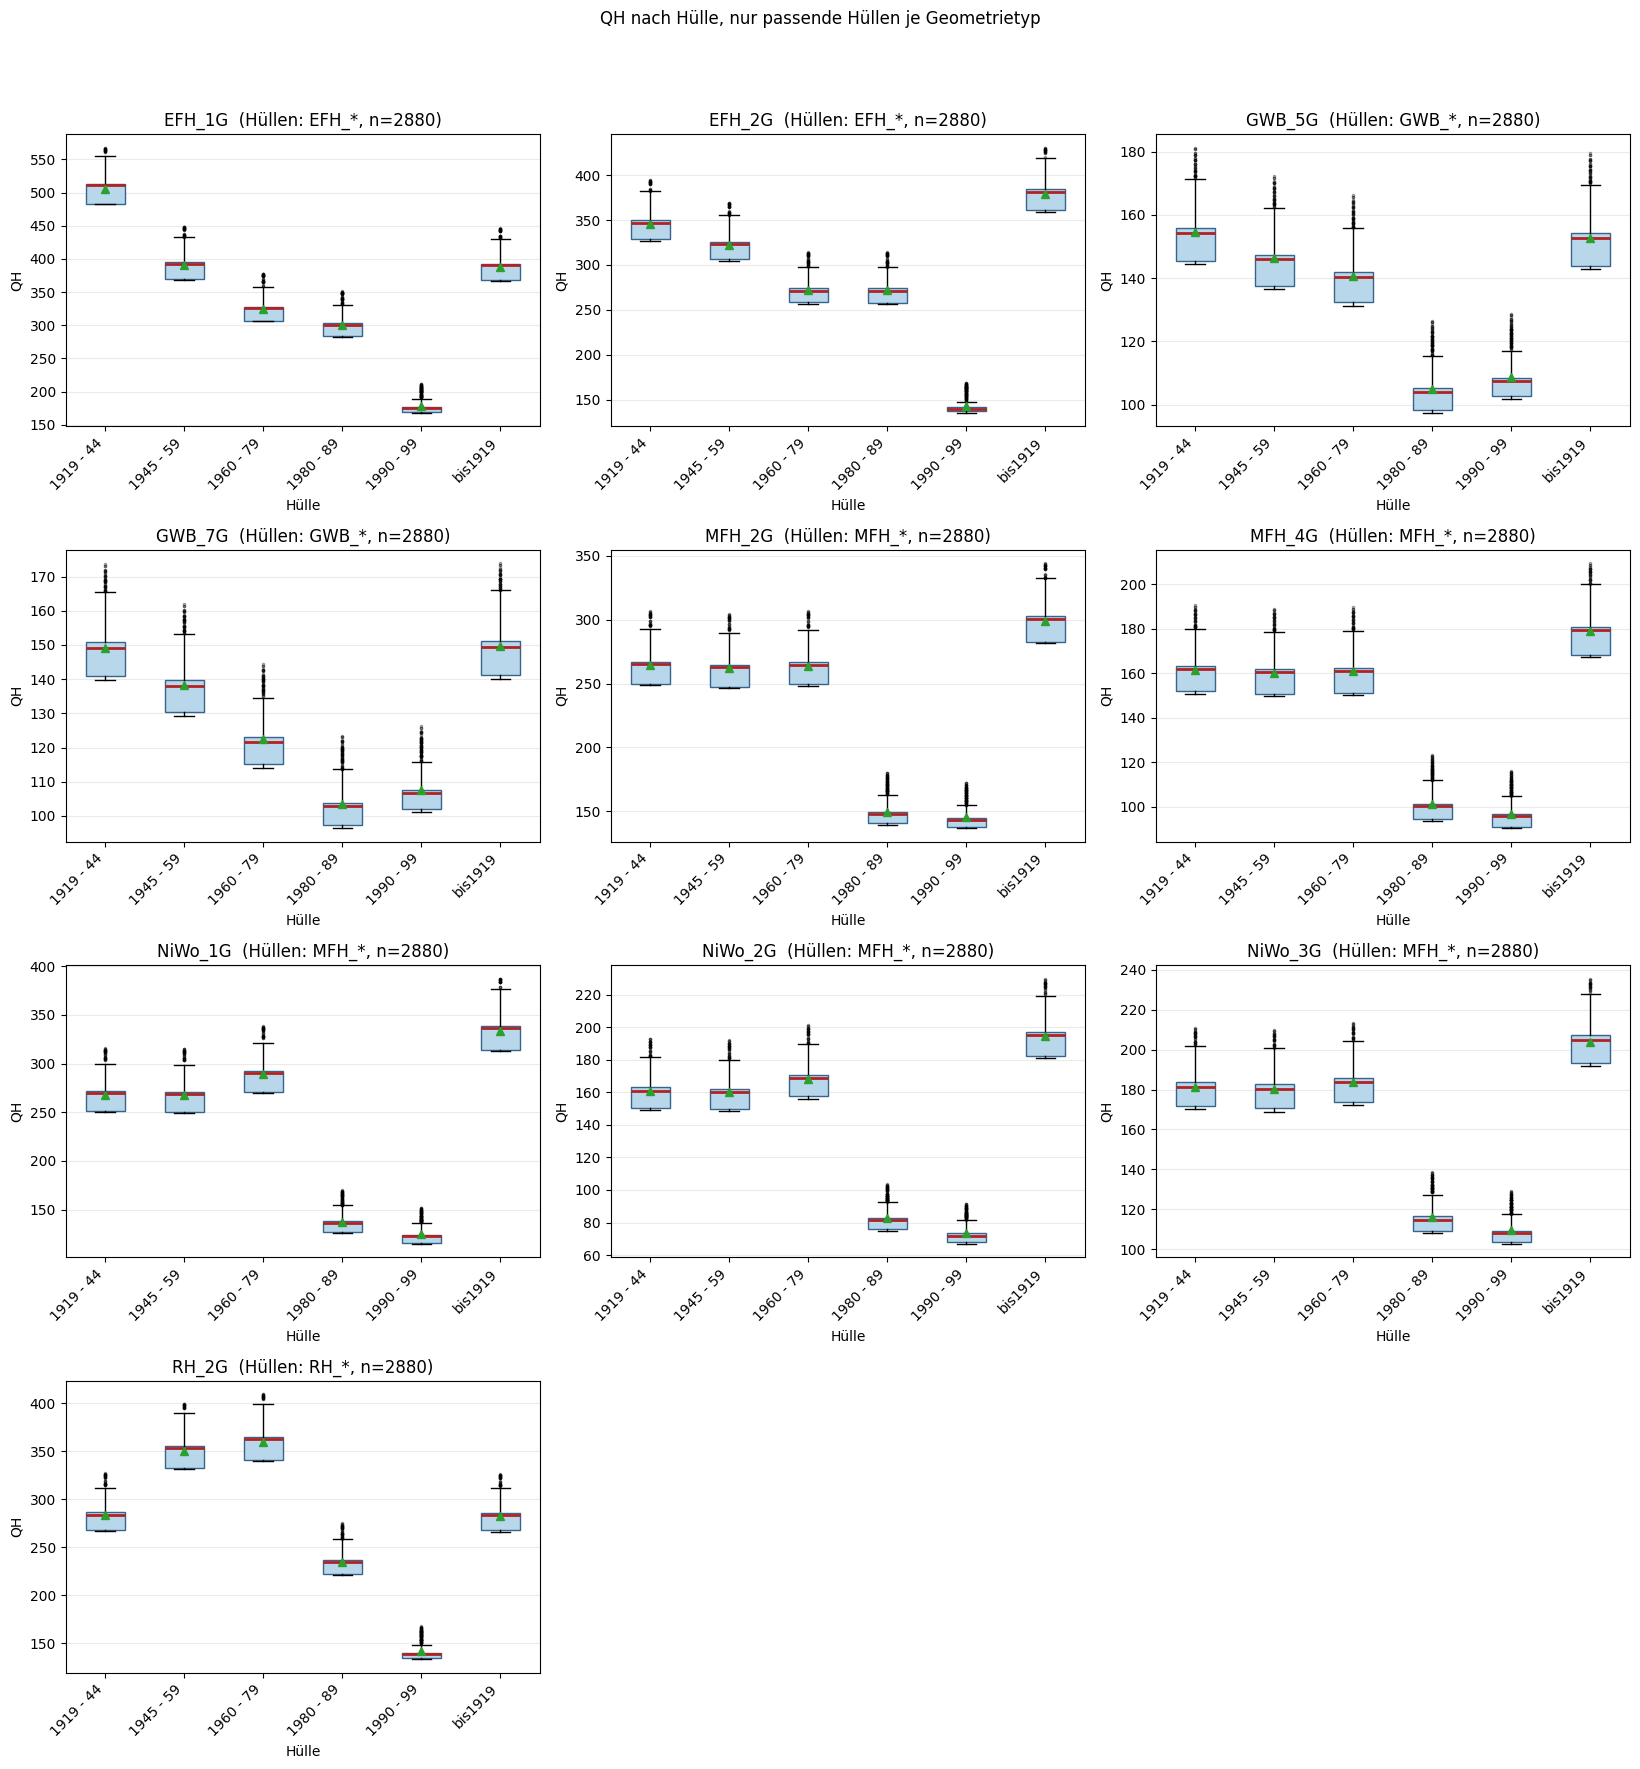

In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

datei = Path(r"C:\Users\ma0026.NB-MA0026\Documents\peexcel\data\building_typologies\building_sector_v3\scenarios_harmonisiert.parquet")

geo = "preset_recorded_geometry"
huelle = "preset_recorded_hulls"

# Abweichende Präfixe: Geometrie-Präfix -> Hüllen-Präfix
praefix_alias = {"NiWo": "MFH"}

def huellen_praefix(geometrie: str) -> str:
    p = geometrie.split("_", 1)[0]
    return praefix_alias.get(p, p) + "_"

df = pd.read_parquet(datei, columns=[geo, huelle, "QH"])
df["QH"] = pd.to_numeric(df["QH"], errors="raise")
df = df.dropna(subset=[geo, huelle, "QH"]).copy()
df[[geo, huelle]] = df[[geo, huelle]].astype("string")

# Nur passende Kombinationen behalten
passt = [
    h.startswith(huellen_praefix(g))
    for g, h in zip(df[geo], df[huelle])
]
verworfen = df.loc[[not p for p in passt], [geo, huelle]].drop_duplicates()
df = df.loc[passt]

typen = sorted(df[geo].unique())

# Kontrolle der Zuordnung
print("Geometrietyp -> Präfix -> Hüllen")
for t in typen:
    hs = sorted(df.loc[df[geo] == t, huelle].unique())
    print(f"{t} -> {huellen_praefix(t)} -> {hs}")
print(f"\nAusgeschlossene Kombinationen: {len(verworfen)}")

ohne_daten = set(pd.read_parquet(datei, columns=[geo])[geo].dropna().astype("string")) - set(typen)
if ohne_daten:
    print("Geometrietypen ohne passende Hülle:", sorted(ohne_daten))
if not typen:
    raise ValueError("Keine passenden Kombinationen gefunden. Präfixe prüfen.")

# Grafik
n_spalten = min(3, len(typen))
n_zeilen = (len(typen) + n_spalten - 1) // n_spalten

fig, achsen = plt.subplots(
    n_zeilen, n_spalten, squeeze=False,
    figsize=(5.5 * n_spalten, 4.5 * n_zeilen),
)

for ax, typ in zip(achsen.ravel(), typen):
    teil = df.loc[df[geo] == typ]
    huellen = sorted(teil[huelle].unique())
    gruppen = [teil.loc[teil[huelle] == h, "QH"].to_numpy() for h in huellen]

    ax.boxplot(
        gruppen, showmeans=True, patch_artist=True,
        boxprops=dict(facecolor="#b9d7ea", edgecolor="#36648b"),
        medianprops=dict(color="#b22222", linewidth=2),
        flierprops=dict(marker=".", markersize=3, alpha=0.4),
    )
    pre = huellen_praefix(typ)
    ax.set_xticks(range(1, len(huellen) + 1))
    ax.set_xticklabels([h.removeprefix(pre) for h in huellen],
                       rotation=45, ha="right")
    ax.set_title(f"{typ}  (Hüllen: {pre}*, n={len(teil)})")
    ax.set_xlabel("Hülle")
    ax.set_ylabel("QH")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

for ax in achsen.ravel()[len(typen):]:
    ax.axis("off")

fig.suptitle("QH nach Hülle, nur passende Hüllen je Geometrietyp")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
# fig.savefig("QH_huelle_geometrietyp.png", dpi=200, bbox_inches="tight")

Geometrietyp -> Hüllen in Plot-Reihenfolge
EFH_1G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
EFH_2G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
GWB_5G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
GWB_7G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
MFH_2G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
MFH_4G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
NiWo_1G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
NiWo_2G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
NiWo_3G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']
RH_2G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99']


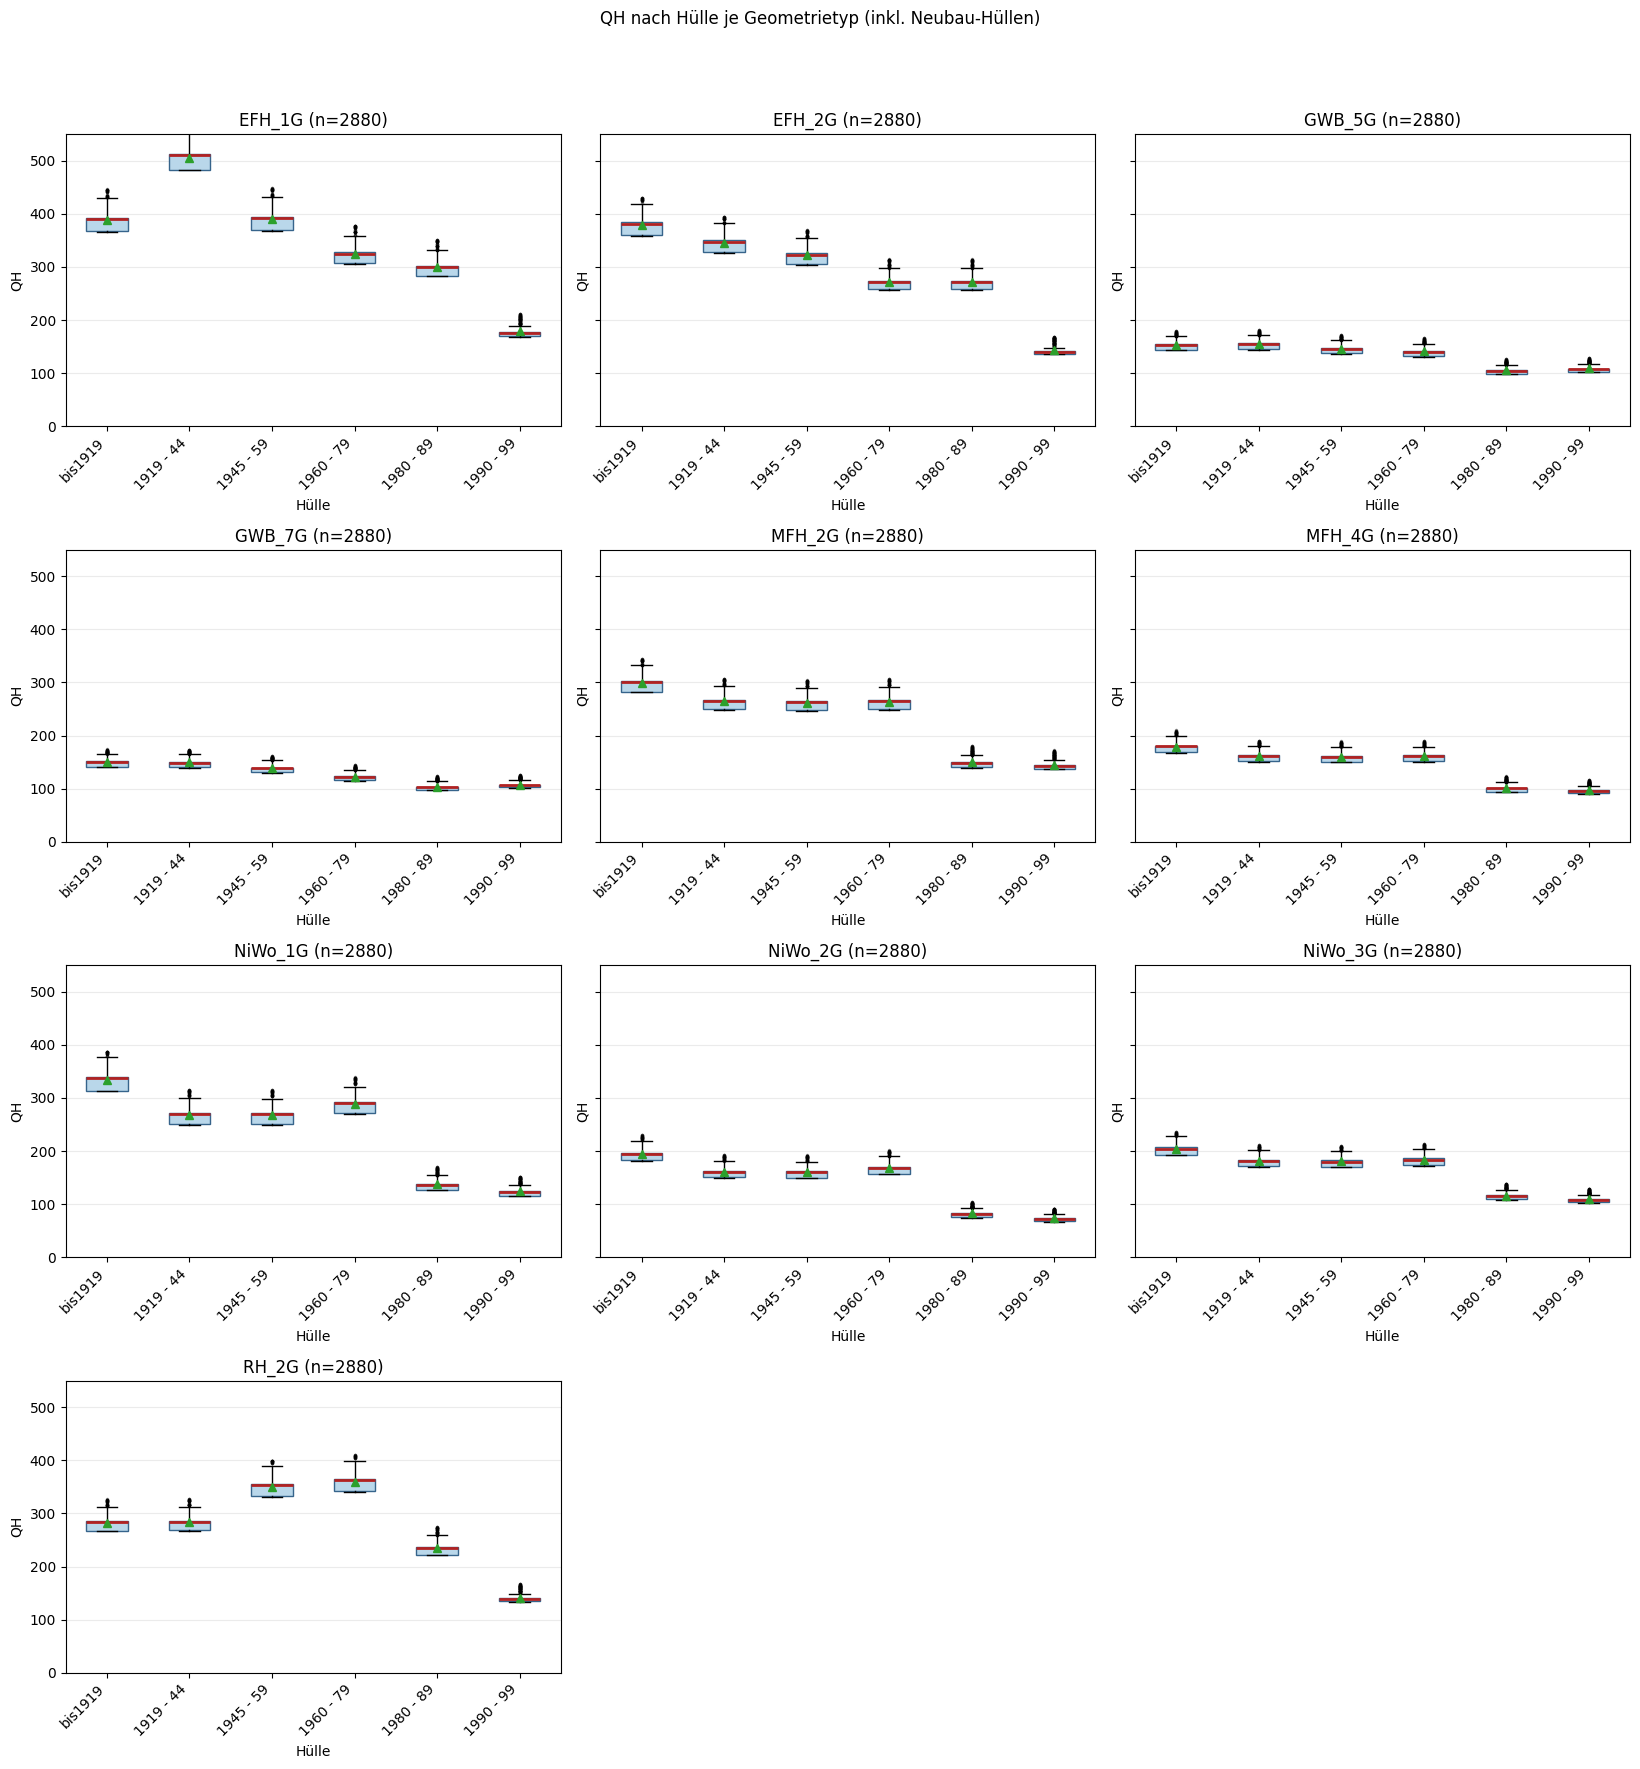

Werte außerhalb (0, 550): 33


In [ ]:
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

datei = Path(r"C:\Users\ma0026.NB-MA0026\Documents\peexcel\data\building_typologies\building_sector_v3\scenarios_harmonisiert.parquet")

geo = "preset_recorded_geometry"
huelle = "preset_recorded_hulls"
praefix_alias = {"NiWo": "MFH"}
y_grenzen = (0, 550)

def huellen_praefix(geometrie: str) -> str:
    p = geometrie.split("_", 1)[0]
    return praefix_alias.get(p, p) + "_"

import re

neubau_huellen = ["WD1", "WD2", "WD3"]
neubau_label = {"WD1": "Neubau 10cm", "WD2": "Neubau 20cm", "WD3": "Neubau 30cm"}
# Annahme: WD1 = 10 cm, WD2 = 20 cm, WD3 = 30 cm. Bitte prüfen.

def ist_neubau(h: str, pre: str = "") -> bool:
    return h in neubau_huellen

def kurzname(h: str, pre: str) -> str:
    return neubau_label.get(h, h.removeprefix(pre))

def sortierschluessel(h: str, pre: str):
    if ist_neubau(h):
        return (2, neubau_huellen.index(h), h)
    name = h.removeprefix(pre).lower()
    zahl = re.search(r"\d+", name)
    zahl = int(zahl.group()) if zahl else 0
    return (0 if name.startswith("bis") else 1, zahl, name)


df = pd.read_parquet(datei, columns=[geo, huelle, "QH"])
df["QH"] = pd.to_numeric(df["QH"], errors="raise")
df = df.dropna(subset=[geo, huelle, "QH"]).copy()
df[[geo, huelle]] = df[[geo, huelle]].astype("string")

# Filter: passendes Präfix ODER Neubau-Hülle
behalten = [
    h.startswith(huellen_praefix(g)) or ist_neubau(h)
    for g, h in zip(df[geo], df[huelle])
]
df = df.loc[behalten]
typen = sorted(df[geo].unique())

print("Geometrietyp -> Hüllen in Plot-Reihenfolge")
for t in typen:
    pre = huellen_praefix(t)
    hs = sorted(df.loc[df[geo] == t, huelle].unique(),
                key=lambda h: sortierschluessel(h, pre))
    print(f"{t}: {[kurzname(h, pre) for h in hs]}")
if not typen:
    raise ValueError("Keine passenden Kombinationen gefunden. Präfixe prüfen.")

n_spalten = min(3, len(typen))
n_zeilen = (len(typen) + n_spalten - 1) // n_spalten
fig, achsen = plt.subplots(
    n_zeilen, n_spalten, sharey=True, squeeze=False,
    figsize=(5.5 * n_spalten, 4.5 * n_zeilen),
)

for ax, typ in zip(achsen.ravel(), typen):
    pre = huellen_praefix(typ)
    teil = df.loc[df[geo] == typ]
    huellen = sorted(teil[huelle].unique(),
                     key=lambda h: sortierschluessel(h, pre))
    gruppen = [teil.loc[teil[huelle] == h, "QH"].to_numpy() for h in huellen]

    ax.boxplot(
        gruppen, showmeans=True, patch_artist=True,
        boxprops=dict(facecolor="#b9d7ea", edgecolor="#36648b"),
        medianprops=dict(color="#b22222", linewidth=2),
        flierprops=dict(marker=".", markersize=3, alpha=0.4),
    )
    ax.set_xticks(range(1, len(huellen) + 1))
    ax.set_xticklabels([kurzname(h, pre) for h in huellen],
                       rotation=45, ha="right")
    ax.set_ylim(*y_grenzen)
    ax.set_title(f"{typ} (n={len(teil)})")
    ax.set_xlabel("Hülle")
    ax.set_ylabel("QH")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

for ax in achsen.ravel()[len(typen):]:
    ax.axis("off")

fig.suptitle("QH nach Hülle je Geometrietyp (inkl. Neubau-Hüllen)")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

ausserhalb = (df["QH"] < y_grenzen[0]) | (df["QH"] > y_grenzen[1])
print(f"Werte außerhalb {y_grenzen}: {int(ausserhalb.sum())}")
# fig.savefig("QH_huelle_geometrietyp.png", dpi=200, bbox_inches="tight")

Geometrietyp -> Hüllen in Plot-Reihenfolge
EFH_1G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 'WD2 (2/3, 20cm)', 'WD3 (3/3, 30cm)']
EFH_2G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 'WD2 (2/3, 20cm)', 'WD3 (3/3, 30cm)']
GWB_5G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 'WD2 (2/3, 20cm)', 'WD3 (3/3, 30cm)']
GWB_7G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 'WD2 (2/3, 20cm)', 'WD3 (3/3, 30cm)']
MFH_2G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 'WD2 (2/3, 20cm)', 'WD3 (3/3, 30cm)']
MFH_4G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 'WD2 (2/3, 20cm)', 'WD3 (3/3, 30cm)']
NiWo_1G: ['bis1919', '1919 - 44', '1945 - 59', '1960 - 79', '1980 - 89', '1990 - 99', 'WD1 (1/3, 10cm)', 

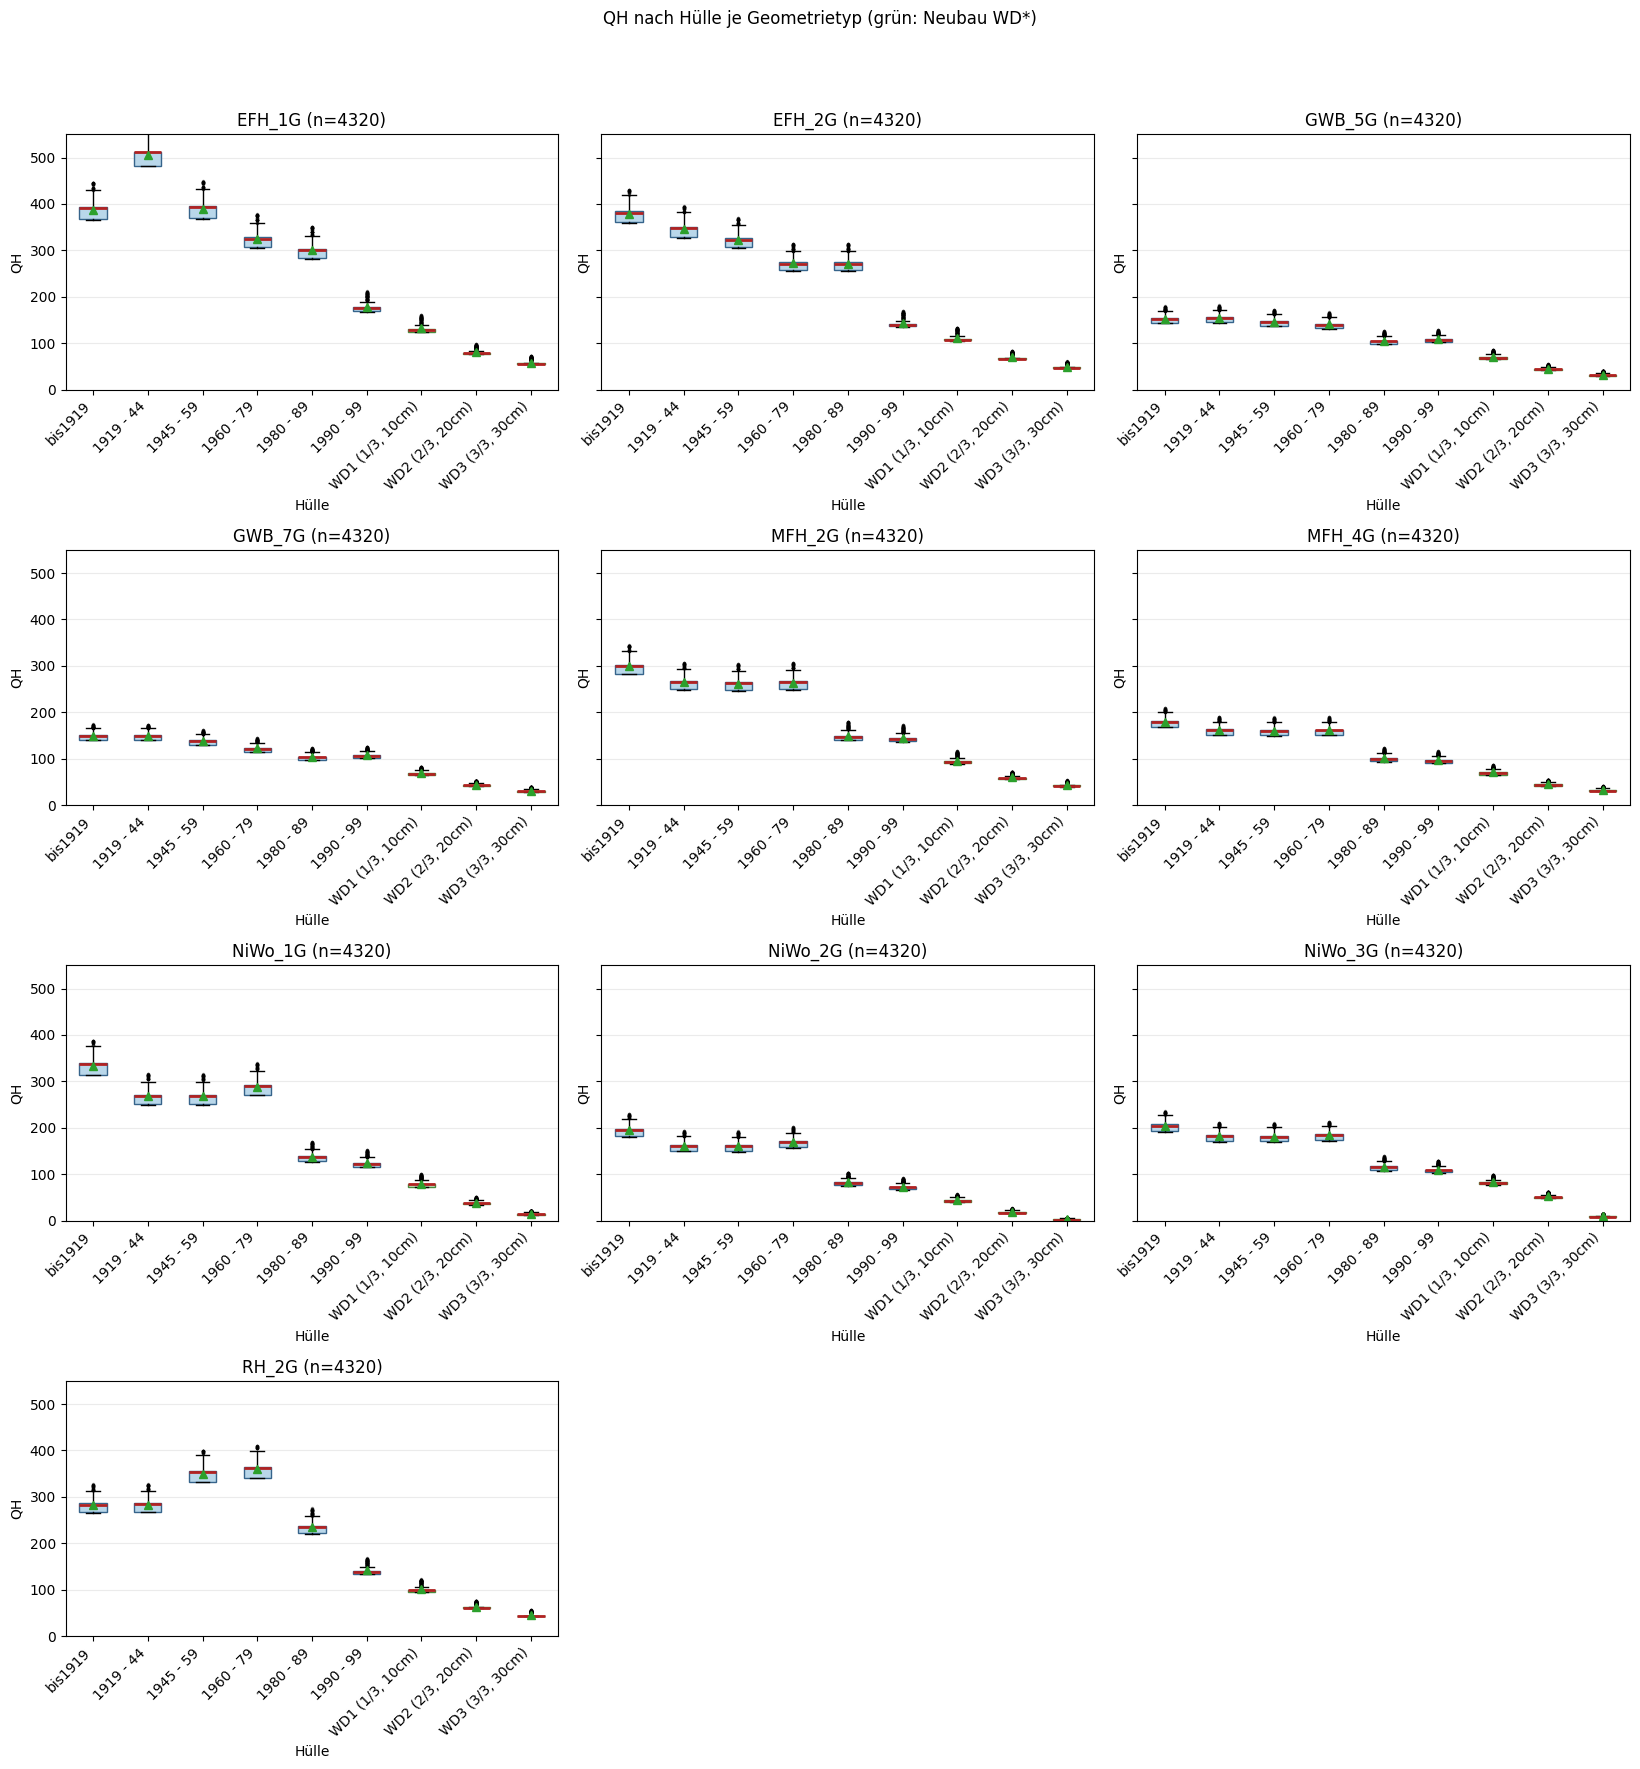

Werte außerhalb (0, 550): 33


In [10]:
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ── Einstellungen ────────────────────────────────────────────────────
datei = Path(r"C:\Users\ma0026.NB-MA0026\Documents\peexcel\data\building_typologies\building_sector_v3\scenarios_harmonisiert.parquet")

geo = "preset_recorded_geometry"
huelle = "preset_recorded_hulls"
wert = "QH"

praefix_alias = {"NiWo": "MFH"}      # Geometrie-Präfix -> Hüllen-Präfix
y_grenzen = (0, 550)
neubau_muster = re.compile(r"^(?:[A-Za-z]+_)?WD\d*", re.IGNORECASE)
neubau_label = {}                    # optional, z. B. {"WD1": "WD1 (10 cm)"}

# ── Hilfsfunktionen ──────────────────────────────────────────────────
def huellen_praefix(geometrie: str) -> str:
    p = geometrie.split("_", 1)[0]
    return praefix_alias.get(p, p) + "_"

def ist_neubau(h: str) -> bool:
    return neubau_muster.match(h) is not None

def kurzname(h: str, pre: str) -> str:
    name = h.removeprefix(pre)
    return neubau_label.get(name, name)

def sortierschluessel(h: str, pre: str):
    name = h.removeprefix(pre).lower()
    zahl = re.search(r"\d+", name)
    zahl = int(zahl.group()) if zahl else 0
    if name.startswith("bis"):
        gruppe = 0
    elif ist_neubau(h):
        gruppe = 2
    else:
        gruppe = 1
    return (gruppe, zahl, name)

# ── Daten laden ──────────────────────────────────────────────────────
df = pd.read_parquet(datei, columns=[geo, huelle, wert])
df[wert] = pd.to_numeric(df[wert], errors="raise")
df = df.dropna(subset=[geo, huelle, wert]).copy()
df[[geo, huelle]] = df[[geo, huelle]].astype("string")

# Passendes Präfix ODER Neubau-Hülle (WD*)
behalten = [
    h.startswith(huellen_praefix(g)) or ist_neubau(h)
    for g, h in zip(df[geo], df[huelle])
]
df = df.loc[behalten]
typen = sorted(df[geo].unique())

if not typen:
    raise ValueError("Keine passenden Kombinationen gefunden. Präfixe prüfen.")

# Kontrolle der Zuordnung
print("Geometrietyp -> Hüllen in Plot-Reihenfolge")
for t in typen:
    pre = huellen_praefix(t)
    hs = sorted(df.loc[df[geo] == t, huelle].unique(),
                key=lambda h: sortierschluessel(h, pre))
    print(f"{t}: {[kurzname(h, pre) for h in hs]}")

# ── Grafik ───────────────────────────────────────────────────────────
n_spalten = min(3, len(typen))
n_zeilen = (len(typen) + n_spalten - 1) // n_spalten

fig, achsen = plt.subplots(
    n_zeilen, n_spalten, sharey=True, squeeze=False,
    figsize=(5.5 * n_spalten, 4.5 * n_zeilen),
)

for ax, typ in zip(achsen.ravel(), typen):
    pre = huellen_praefix(typ)
    teil = df.loc[df[geo] == typ]
    huellen = sorted(teil[huelle].unique(),
                     key=lambda h: sortierschluessel(h, pre))
    gruppen = [teil.loc[teil[huelle] == h, wert].to_numpy() for h in huellen]

    ax.boxplot(
        gruppen, showmeans=True, patch_artist=True,
        boxprops=dict(facecolor="#b9d7ea", edgecolor="#36648b"),
        medianprops=dict(color="#b22222", linewidth=2),
        flierprops=dict(marker=".", markersize=3, alpha=0.4),
    )

    # Neubau-Boxen farblich absetzen
    for box, h in zip(ax.patches, huellen):
        if ist_neubau(h):
            box.set_facecolor("#c9e4c5")
            box.set_edgecolor("#4b8a3f")

    ax.set_xticks(range(1, len(huellen) + 1))
    ax.set_xticklabels([kurzname(h, pre) for h in huellen],
                       rotation=45, ha="right")
    ax.set_ylim(*y_grenzen)
    ax.set_title(f"{typ} (n={len(teil)})")
    ax.set_xlabel("Hülle")
    ax.set_ylabel(wert)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

for ax in achsen.ravel()[len(typen):]:
    ax.axis("off")

fig.suptitle("QH nach Hülle je Geometrietyp (grün: Neubau WD*)")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

ausserhalb = (df[wert] < y_grenzen[0]) | (df[wert] > y_grenzen[1])
print(f"Werte außerhalb {y_grenzen}: {int(ausserhalb.sum())}")
# fig.savefig("QH_huelle_geometrietyp.png", dpi=200, bbox_inches="tight")

Geometrieklasse -> enthaltene Geometrietypen
EFH: ['EFH_1G', 'EFH_2G']
RH: ['RH_2G']
MFH: ['MFH_2G', 'MFH_4G']
GWB: ['GWB_5G', 'GWB_7G']
NiWo: ['NiWo_1G', 'NiWo_2G', 'NiWo_3G']


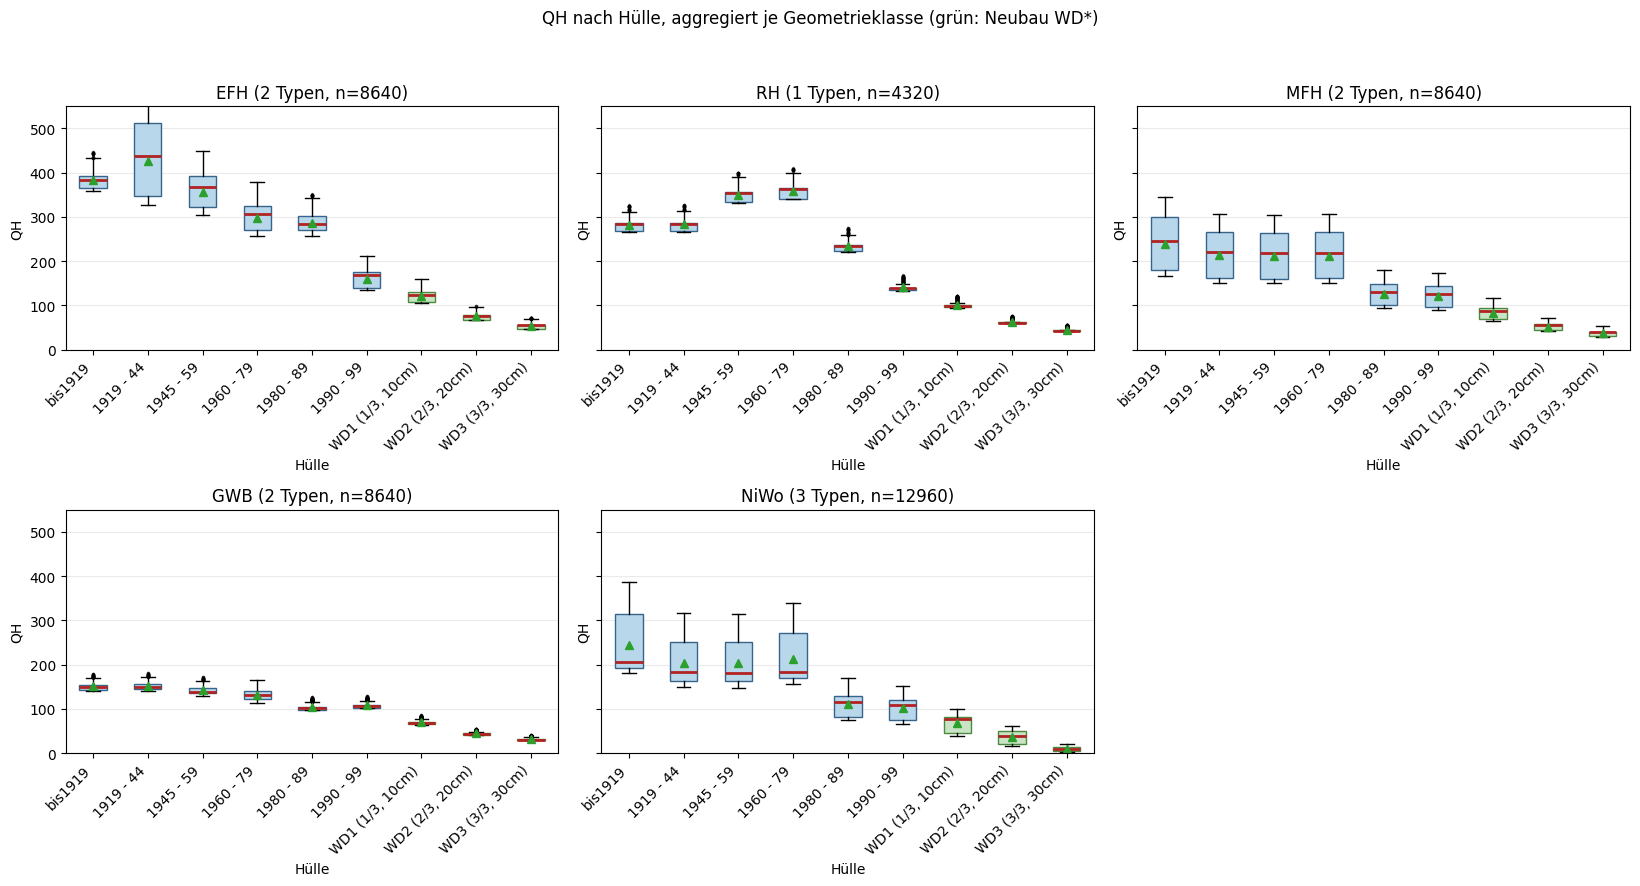

In [11]:
klassen_reihenfolge = ["EFH", "RH", "MFH", "GWB", "NiWo"]

agg = df.copy()
agg["geometrieklasse"] = agg[geo].str.split("_", n=1).str[0]

vorhanden = agg["geometrieklasse"].unique().tolist()
klassen = (
    [k for k in klassen_reihenfolge if k in vorhanden]
    + sorted(set(vorhanden) - set(klassen_reihenfolge))
)

print("Geometrieklasse -> enthaltene Geometrietypen")
for k in klassen:
    print(f"{k}: {sorted(agg.loc[agg['geometrieklasse'] == k, geo].unique())}")

n_spalten = min(3, len(klassen))
n_zeilen = (len(klassen) + n_spalten - 1) // n_spalten

fig, achsen = plt.subplots(
    n_zeilen, n_spalten, sharey=True, squeeze=False,
    figsize=(5.5 * n_spalten, 4.5 * n_zeilen),
)

for ax, klasse in zip(achsen.ravel(), klassen):
    pre = praefix_alias.get(klasse, klasse) + "_"
    teil = agg.loc[agg["geometrieklasse"] == klasse]
    huellen = sorted(teil[huelle].unique(),
                     key=lambda h: sortierschluessel(h, pre))
    gruppen = [teil.loc[teil[huelle] == h, wert].to_numpy() for h in huellen]

    ax.boxplot(
        gruppen, showmeans=True, patch_artist=True,
        boxprops=dict(facecolor="#b9d7ea", edgecolor="#36648b"),
        medianprops=dict(color="#b22222", linewidth=2),
        flierprops=dict(marker=".", markersize=3, alpha=0.4),
    )

    for box, h in zip(ax.patches, huellen):
        if ist_neubau(h):
            box.set_facecolor("#c9e4c5")
            box.set_edgecolor("#4b8a3f")

    n_typen = teil[geo].nunique()
    ax.set_xticks(range(1, len(huellen) + 1))
    ax.set_xticklabels([kurzname(h, pre) for h in huellen],
                       rotation=45, ha="right")
    ax.set_ylim(*y_grenzen)
    ax.set_title(f"{klasse} ({n_typen} Typen, n={len(teil)})")
    ax.set_xlabel("Hülle")
    ax.set_ylabel(wert)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

for ax in achsen.ravel()[len(klassen):]:
    ax.axis("off")

fig.suptitle("QH nach Hülle, aggregiert je Geometrieklasse (grün: Neubau WD*)")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
# fig.savefig("QH_huelle_geometrieklasse.png", dpi=200, bbox_inches="tight")